# Three-mixture classifier: robusta + chicory, arabica + chicory, arabica + robusta + chicory

**Assumption (from the chemistry checks in `arabica_robusta_models_and_classifier.ipynb`):** the "AR" series is a
three-component mixture, a mixed arabica–robusta coffee base plus chicory. The classes are therefore defined by the
**coffee base**:

| Class | Coffee base | Dishes | Scan sets (days) |
|---|---|---|---|
| **RBCH** robusta + chicory | robusta | 33 (0–50 % chicory) | S1 1 Sep, S2 4 Sep, S3 8 Sep |
| **ABCH** arabica + chicory | arabica | 33 (0–50 % chicory) | S1 1 Sep, S2 4 Sep, S3 8 Sep |
| **ARC** arabica + robusta + chicory | arabica + robusta | 33 (all "AR" dishes except the 13:30 "AR 50-50") | 12:00 4 Sep, 13:30 4 Sep, 7 Sep |

**Methods** (the standard set for spectral classification): PLS-DA, PCA-LDA, multinomial logistic regression, linear SVM,
kNN on PCA scores, Random Forest, and SIMCA (one PCA model per class, assignment by scaled residual + leverage distance).
**Features:** (a) absorbance + offset, 1000–2450 nm; (b) first derivative on the chemistry bands 1650–1800 + 2150–2400 nm.
Training unit: super-patches (trimmed, about 8 patches each), as in all project models; a **dish** is classified by
averaging its super-patches' class scores.

**Validation, fully nested:**
1. *Leave one scan set out* (9 folds): every dish is classified by a model that never saw its scan; the setting of each
   method is tuned inside the fold by leave-one-scan-set-out on the remaining 8 sets.
2. *Leave one day out* (4 folds: 1, 4, 7, 8 Sep), stricter: all scans of a day are held out together.

Score: dish-level **balanced accuracy** (mean of the three class recalls), so the three classes count equally.
Outputs: `three_mixture_classifier/`.

## 1. Data: super-patches of the three mixtures

In [1]:
import os
import json, pickle, warnings, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import savgol_filter
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
warnings.filterwarnings("ignore")

BASE = Path(os.environ.get("COFFEE_DATA", "."))
OUT = BASE / "three_mixture_classifier"; OUT.mkdir(exist_ok=True)
_ns = {}
exec((BASE / "coffee_app" / "train_app_models.py").read_text().split("fam = {}")[0], _ns)   # load(), preprocess(), units(), COLS
load, preprocess, units, COLS = _ns["load"], _ns["preprocess"], _ns["units"], _ns["COLS"]
WL = np.array([float(c) for c in COLS])
CL = ["RBCH", "ABCH", "ARC"]
NAME = {"RBCH": "robusta + chicory", "ABCH": "arabica + chicory", "ARC": "arabica + robusta + chicory"}
DAY = {("RBCH", 1): "1 Sep", ("RBCH", 2): "4 Sep", ("RBCH", 3): "8 Sep", ("ABCH", 1): "1 Sep", ("ABCH", 2): "4 Sep",
       ("ABCH", 3): "8 Sep", ("ARC", 1): "4 Sep", ("ARC", 2): "4 Sep", ("ARC", 3): "7 Sep"}

parts = []
for F in ("RBCH", "ABCH"):
    D = load(F); ZU, UM, _ = units(D, preprocess(D[COLS].values))
    parts.append((ZU, UM.assign(cls=F)))
AR = pd.read_csv(BASE / "arabica_robusta_out" / "training_samples.csv")
# the 13:30 scan set's "AR 50-50" dishes are removed (session 2; the 12:00 "AR 50-50" stays)
Dar = AR[(AR.role == "calibration") & ~((AR.day == 2) & (AR.label == "AR[50:50]"))].reset_index(drop=True)
Dar["session"] = Dar.day.astype(int); Dar["chicory_pct"] = Dar.robusta_pct     # trimming reference only
ZU, UM, _ = units(Dar, preprocess(Dar[COLS].values)); parts.append((ZU, UM.assign(cls="ARC")))
X_STD = np.vstack([p[0] for p in parts])
M = pd.concat([p[1] for p in parts], ignore_index=True)
M["scanset"] = M.cls + "-S" + M.session.astype(str)
M["day"] = [DAY[(c, s)] for c, s in zip(M.cls, M.session)]
y = M.cls.map({c: i for i, c in enumerate(CL)}).to_numpy()
G = M.group.astype(str).to_numpy()
CHEM = ((WL >= 1650) & (WL <= 1800)) | ((WL >= 2150) & (WL <= 2400))
FEATURES = {"absorbance + offset": X_STD,
            "chemistry bands, 1st derivative": savgol_filter(X_STD, 15, 2, deriv=1, axis=1)[:, CHEM]}
DISH_CLASS = M.groupby("group").cls.first()
print(f"{len(M)} super-patches, {M.group.nunique()} dishes")
print(M.groupby(["cls", "scanset", "day"]).agg(dishes=("group", "nunique"), superpatches=("group", "size")).to_string())

1579 super-patches, 99 dishes
                    dishes  superpatches
cls  scanset day                        
ABCH ABCH-S1 1 Sep       3            48
     ABCH-S2 4 Sep      15           240
     ABCH-S3 8 Sep      15           240
ARC  ARC-S1  4 Sep       9           144
     ARC-S2  4 Sep       9           144
     ARC-S3  7 Sep      15           239
RBCH RBCH-S1 1 Sep       3            44
     RBCH-S2 4 Sep      15           240
     RBCH-S3 8 Sep      15           240


## 2. Methods and the nested validation

Each method returns a score per class; a dish takes the class with the highest mean score over its super-patches.
Settings are tried from simplest to most complex and the first best (by inner balanced accuracy) is kept.

In [2]:
def simca_scores(Xtr, ytr, Xte, k):
    out = np.full((len(Xte), 3), -np.inf)
    for c in np.unique(ytr):
        Xc = Xtr[ytr == c]; p = PCA(min(k, len(Xc) - 1)).fit(Xc)
        T = p.transform(Xc); q = ((Xc - p.inverse_transform(T)) ** 2).sum(1); t2 = (T ** 2 / p.explained_variance_).sum(1)
        q0, t0 = np.percentile(q, 95), np.percentile(t2, 95)
        Te = p.transform(Xte); qe = ((Xte - p.inverse_transform(Te)) ** 2).sum(1); te_ = (Te ** 2 / p.explained_variance_).sum(1)
        out[:, c] = -(qe / q0 + te_ / t0)
    return out

def class_scores(method, prm, Xtr, ytr, Xte):
    present = np.unique(ytr)
    if method == "SIMCA":
        return simca_scores(Xtr, ytr, Xte, prm)
    if method == "PLS-DA":
        S = PLSRegression(prm).fit(Xtr, np.eye(3)[ytr]).predict(Xte); S[:, [c for c in range(3) if c not in present]] = -np.inf; return S
    m = {"PCA-LDA": lambda: make_pipeline(PCA(prm), LinearDiscriminantAnalysis()),
         "Logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=prm, max_iter=5000)),
         "Linear SVM": lambda: make_pipeline(StandardScaler(), LinearSVC(C=prm, max_iter=20000)),
         "kNN (PCA scores)": lambda: make_pipeline(PCA(10), KNeighborsClassifier(prm)),
         "Random Forest": lambda: RandomForestClassifier(200, min_samples_leaf=prm, max_features="sqrt", random_state=0, n_jobs=-1)}[method]()
    m.fit(Xtr, ytr)
    raw = m.decision_function(Xte) if method == "Linear SVM" else m.predict_proba(Xte)
    if raw.ndim == 1: raw = np.column_stack([-raw, raw])
    S = np.full((len(Xte), 3), -np.inf); S[:, present] = raw
    return S

GRID = {"PLS-DA": [2, 3, 4, 5, 6, 8, 10, 12], "PCA-LDA": [3, 5, 8, 10, 15, 20], "Logistic regression": [0.001, 0.01, 0.1, 1, 10],
        "Linear SVM": [0.0003, 0.001, 0.01, 0.1, 1], "kNN (PCA scores)": [15, 9, 5, 3], "Random Forest": [10, 3],
        "SIMCA": [1, 2, 3, 4, 6]}
PARAM = {"PLS-DA": "components", "PCA-LDA": "PCA components", "Logistic regression": "C", "Linear SVM": "C",
         "kNN (PCA scores)": "neighbours", "Random Forest": "min leaf", "SIMCA": "components per class"}

def dish_decisions(S, groups):
    d = pd.DataFrame(S, columns=range(3)).replace(-np.inf, -1e9).groupby(groups).mean()
    return d.idxmax(axis=1)

def balanced_accuracy(pred):          # pred: Series dish -> class index
    true = DISH_CLASS.loc[pred.index].map({c: i for i, c in enumerate(CL)})
    return float(np.mean([(pred[true == c] == c).mean() for c in range(3) if (true == c).any()]))

def nested(method, X, outer_ids):
    preds, chosen = [], []
    sets = M.scanset.to_numpy()
    for f in pd.unique(outer_ids):
        te = outer_ids == f; tr = ~te
        best = None
        for prm in GRID[method]:
            inner = []
            for s in pd.unique(sets[tr]):
                ite = tr & (sets == s); itr = tr & ~ite
                inner.append(dish_decisions(class_scores(method, prm, X[itr], y[itr], X[ite]), G[ite]))
            acc = balanced_accuracy(pd.concat(inner))
            if best is None or acc > best[0] + 1e-9: best = (acc, prm)
        preds.append(dish_decisions(class_scores(method, best[1], X[tr], y[tr], X[te]), G[te]))
        chosen.append(best[1])
    return pd.concat(preds), chosen

## 3. Leave one scan set out (9 folds), every method and feature set

In [3]:
RES, PRED = [], {}
t0 = time.time()
for fname, X in FEATURES.items():
    for method in GRID:
        pred, chosen = nested(method, X, M.scanset.to_numpy())
        PRED[(fname, method, "scanset")] = pred
        true = DISH_CLASS.loc[pred.index]
        RES.append(dict(features=fname, method=method, balanced_accuracy=balanced_accuracy(pred),
                        correct=f"{int((pred.map(dict(enumerate(CL))) == true).sum())}/{len(pred)}",
                        **{f"{c} recall": f"{int(((true == c) & (pred.map(dict(enumerate(CL))) == c)).sum())}/{int((true == c).sum())}" for c in CL},
                        settings_per_fold=" ".join(map(str, chosen))))
        print(f"{fname:32s} {method:20s} balanced accuracy {RES[-1]['balanced_accuracy']:.3f}   ({time.time() - t0:.0f} s)", flush=True)
SCAN = pd.DataFrame(RES).sort_values("balanced_accuracy", ascending=False)
pd.set_option("display.width", 220)
print(); print(SCAN.round(3).to_string(index=False))
SCAN.to_csv(OUT / "leave_one_scanset_out.csv", index=False)

absorbance + offset              PLS-DA               balanced accuracy 0.707   (6 s)


absorbance + offset              PCA-LDA              balanced accuracy 0.949   (38 s)


absorbance + offset              Logistic regression  balanced accuracy 0.949   (74 s)


absorbance + offset              Linear SVM           balanced accuracy 0.788   (88 s)


absorbance + offset              kNN (PCA scores)     balanced accuracy 0.677   (112 s)


absorbance + offset              Random Forest        balanced accuracy 0.798   (185 s)


... (5 outputs left out)

chemistry bands, 1st derivative  kNN (PCA scores)     balanced accuracy 0.636   (313 s)


chemistry bands, 1st derivative  Random Forest        balanced accuracy 0.646   (385 s)


chemistry bands, 1st derivative  SIMCA                balanced accuracy 0.848   (391 s)



                       features              method  balanced_accuracy correct RBCH recall ABCH recall ARC recall                         settings_per_fold
            absorbance + offset             PCA-LDA              0.949   94/99       32/33       29/33      33/33                   10 10 20 5 10 5 5 10 15
            absorbance + offset Logistic regression              0.949   94/99       33/33       33/33      28/33                   1 0.1 0.1 1 1 1 1 1 0.1
chemistry bands, 1st derivative Logistic regression              0.929   92/99       31/33       33/33      28/33                10 10 10 10 10 10 10 10 10
            absorbance + offset               SIMCA              0.899   89/99       33/33       33/33      23/33                         6 6 6 6 6 6 4 4 4
chemistry bands, 1st derivative             PCA-LDA              0.859   85/99       33/33       28/33      24/33                 15 20 20 15 20 15 15 20 8
chemistry bands, 1st derivative               SIMCA            

## 4. Leave one day out (stricter), every method on both feature sets

In [4]:
RES2 = []
for fname, X in FEATURES.items():
    for method in GRID:
        pred, chosen = nested(method, X, M.day.to_numpy())
        PRED[(fname, method, "day")] = pred
        true = DISH_CLASS.loc[pred.index]
        RES2.append(dict(features=fname, method=method, balanced_accuracy=balanced_accuracy(pred),
                         correct=f"{int((pred.map(dict(enumerate(CL))) == true).sum())}/{len(pred)}",
                         **{f"{c} recall": f"{int(((true == c) & (pred.map(dict(enumerate(CL))) == c)).sum())}/{int((true == c).sum())}" for c in CL}))
DAYRES = pd.DataFrame(RES2).sort_values("balanced_accuracy", ascending=False)
print(DAYRES.round(3).to_string(index=False))
DAYRES.to_csv(OUT / "leave_one_day_out.csv", index=False)

                       features              method  balanced_accuracy correct RBCH recall ABCH recall ARC recall
            absorbance + offset             PCA-LDA              0.960   95/99       33/33       32/33      30/33
chemistry bands, 1st derivative             PCA-LDA              0.949   94/99       33/33       31/33      30/33
            absorbance + offset          Linear SVM              0.879   87/99       33/33       33/33      21/33
chemistry bands, 1st derivative Logistic regression              0.848   84/99       31/33       29/33      24/33
chemistry bands, 1st derivative          Linear SVM              0.848   84/99       33/33       28/33      23/33
            absorbance + offset Logistic regression              0.848   84/99       31/33       31/33      22/33
chemistry bands, 1st derivative               SIMCA              0.838   83/99       32/33       30/33      21/33
            absorbance + offset               SIMCA              0.828   82/99       33/

## 5. Best classifier: confusion matrices and figure

best by the mean of both validations: ('absorbance + offset', 'PCA-LDA')
                       features              method  balanced_accuracy_scanset  balanced_accuracy_day  mean
            absorbance + offset             PCA-LDA                      0.949                  0.960 0.955
chemistry bands, 1st derivative             PCA-LDA                      0.859                  0.949 0.904
            absorbance + offset Logistic regression                      0.949                  0.848 0.899
chemistry bands, 1st derivative Logistic regression                      0.929                  0.848 0.889
            absorbance + offset               SIMCA                      0.899                  0.828 0.864
chemistry bands, 1st derivative          Linear SVM                      0.838                  0.848 0.843
chemistry bands, 1st derivative               SIMCA                      0.848                  0.838 0.843
            absorbance + offset          Linear SVM            

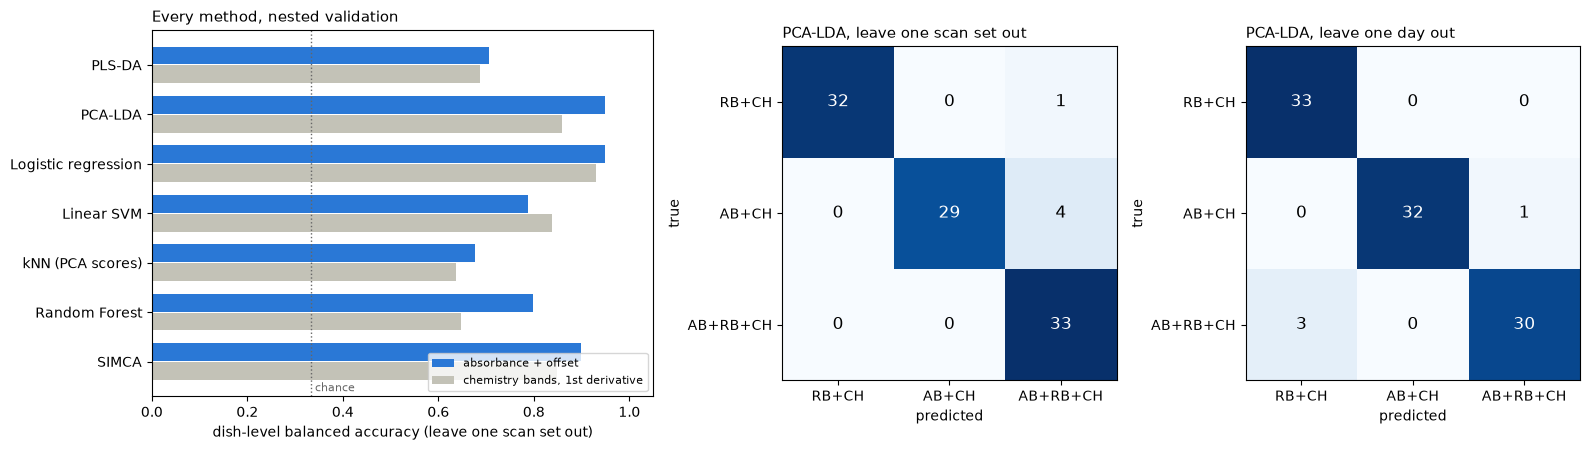


('absorbance + offset', 'PCA-LDA') — scanset:
predicted  RBCH  ABCH  ARC
true                      
RBCH         32     0    1
ABCH          0    29    4
ARC           0     0   33

('absorbance + offset', 'PCA-LDA') — day:
predicted  RBCH  ABCH  ARC
true                      
RBCH         33     0    0
ABCH          0    32    1
ARC           3     0   30


In [5]:
both = SCAN.merge(DAYRES[["features", "method", "balanced_accuracy"]], on=["features", "method"], suffixes=("_scanset", "_day"))
both["mean"] = both[["balanced_accuracy_scanset", "balanced_accuracy_day"]].mean(1)
both = both.sort_values(["mean", "balanced_accuracy_day"], ascending=False)
BEST = tuple(both.iloc[0][["features", "method"]])
print("best by the mean of both validations:", BEST)
print(both[["features", "method", "balanced_accuracy_scanset", "balanced_accuracy_day", "mean"]].round(3).to_string(index=False))

def confusion(pred):
    t = DISH_CLASS.loc[pred.index]; p = pred.map(dict(enumerate(CL)))
    return pd.crosstab(pd.Categorical(t, CL), pd.Categorical(p, CL), rownames=["true"], colnames=["predicted"], dropna=False)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
ax = axs[0]
lab = [f"{m}" for m in GRID]; yy = np.arange(len(lab))
for k, (fname, col) in enumerate(zip(FEATURES, ["#2a78d6", "#c3c2b7"])):
    v = [float(SCAN[(SCAN.features == fname) & (SCAN.method == m)].balanced_accuracy.iloc[0]) for m in GRID]
    ax.barh(yy + (k - .5) * .38, v, height=.36, color=col, label=fname)
ax.axvline(1 / 3, color="0.4", ls=":", lw=1); ax.text(1 / 3, len(lab) - .4, " chance", fontsize=8, color="0.4")
ax.set_yticks(yy, lab); ax.invert_yaxis(); ax.set_xlim(0, 1.05); ax.set_xlabel("dish-level balanced accuracy (leave one scan set out)")
ax.legend(loc="lower right", fontsize=8); ax.set_title("Every method, nested validation", loc="left", fontsize=11)
for ax, scheme, title in [(axs[1], "scanset", "leave one scan set out"), (axs[2], "day", "leave one day out")]:
    C = confusion(PRED[(*BEST, scheme)]).to_numpy()
    ax.imshow(C / C.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(C[i, j]), ha="center", va="center", color="white" if C[i, j] / C[i].sum() > .6 else "black", fontsize=12)
    ax.set_xticks(range(3), ["RB+CH", "AB+CH", "AB+RB+CH"]); ax.set_yticks(range(3), ["RB+CH", "AB+CH", "AB+RB+CH"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{BEST[1]}, {title}", loc="left", fontsize=10.5)
plt.tight_layout(); plt.savefig(OUT / "01_three_mixture_classifier.png", dpi=150, bbox_inches="tight"); plt.show()
for scheme in ("scanset", "day"):
    print(f"\n{BEST} — {scheme}:"); print(confusion(PRED[(*BEST, scheme)]).to_string())

## 6. Final classifier on all data, applied to the test samples J, K, L

In [6]:
fname, method = BEST; X = FEATURES[fname]
sets = M.scanset.to_numpy(); best = None
for prm in GRID[method]:
    inner = [dish_decisions(class_scores(method, prm, X[~(sets == s)], y[~(sets == s)], X[sets == s]), G[sets == s]) for s in pd.unique(sets)]
    acc = balanced_accuracy(pd.concat(inner))
    if best is None or acc > best[0] + 1e-9: best = (acc, prm)
print(f"final {method} on {fname}: {PARAM[method]} = {best[1]}")
# test samples: super-patches of J, K, L (no trimming: no reference composition)
U = AR[AR.label.isin(["J", "K", "L"])].reset_index(drop=True)
Zu = preprocess(U[COLS].values); rows = []
for g_, idx in U.groupby("group").groups.items():
    idx = np.asarray(idx); n = max(1, len(idx) // 8)
    lab = KMeans(n, n_init=5, random_state=0).fit_predict(U.loc[idx, ["patch_row", "patch_col"]].to_numpy(float))
    for c in range(n): rows.append((g_, U.label[idx[0]], Zu[idx[lab == c]].mean(0)))
Xu_std = np.array([r[2] for r in rows])
Xu = Xu_std if fname == "absorbance + offset" else savgol_filter(Xu_std, 15, 2, deriv=1, axis=1)[:, CHEM]
S = class_scores(method, best[1], X, y, Xu)
d = pd.DataFrame(S, columns=CL).assign(label=[r[1] for r in rows], dish=[r[0] for r in rows]).groupby(["label", "dish"]).mean()
d["predicted"] = d[CL].idxmax(axis=1).map(NAME)
print(d.round(3).to_string())
pickle.dump(dict(features=fname, method=method, param=best[1], classes=CL, chem_mask=CHEM, wavelengths=WL),
            open(OUT / "final_classifier_settings.pkl", "wb"))

final PCA-LDA on absorbance + offset: PCA components = 15


                                                             RBCH   ABCH    ARC                    predicted
label dish                                                                                                  
J     stir1_SWIR_384_SN3189_9000us_2026-09-04T115614_raw|J  0.000  1.000  0.000            arabica + chicory
      stir2_SWIR_384_SN3189_9000us_2026-09-04T120652_raw|J  0.000  0.998  0.002            arabica + chicory
      stir3_SWIR_384_SN3189_9000us_2026-09-04T121548_raw|J  0.000  1.000  0.000            arabica + chicory
K     stir1_SWIR_384_SN3189_9000us_2026-09-04T115614_raw|K  0.124  0.001  0.875  arabica + robusta + chicory
      stir2_SWIR_384_SN3189_9000us_2026-09-04T120652_raw|K  0.094  0.001  0.905  arabica + robusta + chicory
      stir3_SWIR_384_SN3189_9000us_2026-09-04T121548_raw|K  0.047  0.001  0.953  arabica + robusta + chicory
L     stir1_SWIR_384_SN3189_9000us_2026-09-04T115614_raw|L  0.000  0.998  0.002            arabica + chicory
      stir2_SWIR_38